In [1]:
import os, subprocess, sys, time, datetime
from zoneinfo import ZoneInfo
KYIV = ZoneInfo('Europe/Kyiv')
T_START = time.time(); _T_CELL = [T_START]


def cell_done(n, name):
    now = time.time()
    fmt = lambda s: str(datetime.timedelta(seconds=int(s)))
    print(f'✅ Cell {n} ({name}) завершено за {fmt(now - _T_CELL[0])} | від старту {fmt(now - T_START)} | '
          f'{datetime.datetime.now(KYIV):%H:%M:%S} (Київ)', flush=True)
    _T_CELL[0] = now


IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive; drive.mount('/content/drive')
    OUT = '/content/drive/MyDrive/HiARN/E5E'
    DATA = '/content/drive/MyDrive/HiARN'
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'anchor-exp', 'tqdm'], check=False)
else:
    OUT = os.environ.get('AXP_OUT', './e5e_out')
    DATA = os.environ.get('E5E_DATA', '.')
os.makedirs(OUT, exist_ok=True)
print('OUT =', OUT, '| DATA =', DATA)
print('CPU:', os.cpu_count())
cell_done(1, 'Drive, пакети')

Mounted at /content/drive
OUT = /content/drive/MyDrive/HiARN/E5E | DATA = /content/drive/MyDrive/HiARN
CPU: 2
✅ Cell 1 (Drive, пакети) завершено за 0:00:32 | від старту 0:00:32 | 13:56:11 (Київ)


In [2]:
import itertools, json, sys, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from multiprocessing import Pool
from sklearn.metrics import f1_score
from sklearn.tree import DecisionTreeClassifier


EPOCHS, LR, TAU0, TAUE, TAUG, GAMMA, RHO, F1_TOL = 500, 3e-3, 0.7, 0.03, 0.98, 2.0, 0.1, 0.01
TOPK, N_CONCEPTS, TOPK_FROM = 3, 8, 0.3
LAMS = [1e-4, 1e-3, 1e-2]
CFGS = ([{'model': 'H2', 'rules': r, 'lam': l} for r in (8, 16, 32) for l in LAMS]
        + [{'model': 'H3c', 'rules': r, 'lam': l} for r in (8, 16) for l in LAMS]
        + [{'model': 'H3', 'rules': 16, 'lam': l} for l in LAMS])
SMOKE = os.environ.get('AXP_SMOKE') == '1'
if SMOKE:
    EPOCHS, CFGS = 15, [c for c in CFGS if c['lam'] == 1e-3][:3] + [c for c in CFGS if c['model'] != 'H2' and c['lam'] == 1e-3]


def ckey(c): return f'{c["model"]}|r={c["rules"]}|lam={c["lam"]}'


class Net(nn.Module):
    def __init__(self, X, y, n_cls, cfg):
        super().__init__()
        F = X.shape[1]
        thr = np.median(X, 0).copy()
        for j in range(F):
            t = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X[:, j:j + 1], y).tree_.threshold[0]
            if t > -2: thr[j] = t
        self.t = nn.Parameter(torch.tensor(thr, dtype=torch.float32))
        self.kind = cfg['model']
        h1 = {'H2': cfg['rules'], 'H3': 32, 'H3c': N_CONCEPTS}[self.kind]
        self.W1 = nn.Parameter(torch.empty(h1, F)); nn.init.xavier_uniform_(self.W1)
        last = h1
        if self.kind != 'H2':
            self.W2 = nn.Parameter(torch.empty(cfg['rules'], h1)); nn.init.xavier_uniform_(self.W2)
            last = cfg['rules']
        self.Wo = nn.Parameter(torch.empty(n_cls, last)); nn.init.xavier_uniform_(self.Wo)
        self.b = nn.Parameter(torch.zeros(n_cls))

    def and_ws(self): return [self.W1] + ([self.W2] if self.kind != 'H2' else [])

    def forward(self, x, tau):
        a = torch.sigmoid(torch.sigmoid(GAMMA * (x - self.t) / tau) @ self.W1.T / tau)
        if self.kind != 'H2': a = torch.sigmoid(a @ self.W2.T / tau)
        return a @ self.Wo.T + self.b

    def discrete(self, x):
        with torch.no_grad():
            def prune(W):
                return (W.abs() >= RHO * W.abs().max(1, keepdim=True).values) & (W.abs() > 0)
            s = (x > self.t).float()
            k1 = prune(self.W1); c = ((s @ (self.W1 * k1).T) > 0).float()
            if self.kind == 'H2':
                alive = (self.Wo.abs().max(0).values >= RHO * self.Wo.abs().max()) & k1.any(1)
                a = c * alive
                lens = k1[alive].sum(1)
                dl = int(lens.sum()); feats = set(torch.where(k1[alive].any(0))[0].tolist())
                return a @ self.Wo.T + self.b, {'dl': dl, 'n_rules': int(alive.sum()),
                        'items_per_rule': float(lens.float().mean()) if alive.any() else 0.0,
                        'expanded_len': float(lens.float().mean()) if alive.any() else 0.0, 'feats': feats}
            k2 = prune(self.W2) & k1.any(1)[None]
            r = ((c @ (self.W2 * k2).T) > 0).float()
            alive = (self.Wo.abs().max(0).values >= RHO * self.Wo.abs().max()) & k2.any(1)
            used_c = k2[alive].any(0)
            conc_len = k1.sum(1)
            dl = int(conc_len[used_c].sum() + k2[alive].sum())
            exp_len = [(conc_len[k2[i]]).sum().item() for i in torch.where(alive)[0]]
            feats = set(torch.where(k1[used_c].any(0))[0].tolist()) if used_c.any() else set()
            return (r * alive) @ self.Wo.T + self.b, {'dl': dl, 'n_rules': int(alive.sum()), 'n_concepts': int(used_c.sum()),
                    'items_per_rule': float(k2[alive].sum(1).float().mean()) if alive.any() else 0.0,
                    'expanded_len': float(np.mean(exp_len)) if exp_len else 0.0, 'feats': feats}


def topk_project(W, k):
    with torch.no_grad():
        idx = W.abs().topk(min(k, W.shape[1]), dim=1).indices
        W.data *= torch.zeros_like(W).scatter_(1, idx, 1.0)


def run(args):
    cfg, X_tr, y_tr, X_te, y_te, seed = args
    torch.set_num_threads(1); torch.manual_seed(seed); np.random.seed(seed)
    n_cls = int(max(y_tr.max(), y_te.max()) + 1)
    m = Net(X_tr, y_tr, n_cls, cfg)
    Xt, yt = torch.tensor(X_tr), torch.tensor(y_tr)
    cnt = np.bincount(y_tr, minlength=n_cls)
    lossf = nn.CrossEntropyLoss(weight=torch.tensor(len(y_tr) / (n_cls * cnt), dtype=torch.float32), label_smoothing=0.05)
    opt = torch.optim.Adam(m.parameters(), lr=LR)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-6)
    lam = cfg['lam']
    for ep in range(EPOCHS):
        tau = TAUE + (TAU0 - TAUE) * TAUG ** ep
        opt.zero_grad()
        loss = lossf(m(Xt, tau), yt) + lam * (sum(W.abs().sum() for W in m.and_ws()) + m.Wo.abs().sum())
        loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        with torch.no_grad():
            for W in m.and_ws() + [m.Wo]:
                W.data = torch.sign(W.data) * (W.data.abs() - lam * LR).clamp(min=0)
        if m.kind == 'H3c' and ep >= int(TOPK_FROM * EPOCHS):
            topk_project(m.W1, TOPK); topk_project(m.W2, TOPK)
        sch.step()
    Xe = torch.tensor(X_te)
    with torch.no_grad():
        p_soft = m(Xe, TAUE).argmax(1).numpy()
        lg, info = m.discrete(Xe)
    p = lg.argmax(1).numpy()
    info['feats'] = sorted(info['feats'])
    return {'rules_f1': float(f1_score(y_te, p, average='macro', zero_division=0)),
            'fidelity': float((p == p_soft).mean()), 'degenerate': bool(len(np.unique(p)) == 1), **info}


def mean(rows, k): return float(np.mean([r[k] for r in rows]))


def jacc(rows):
    s = [set(r['feats']) for r in rows]
    return float(np.mean([len(a & b) / len(a | b) if (a | b) else 1.0 for a, b in itertools.combinations(s, 2)]))


def summ(rows):
    out = {k: round(mean(rows, k), 4) for k in ('rules_f1', 'fidelity', 'dl', 'n_rules', 'items_per_rule', 'expanded_len', 'degenerate')}
    if 'n_concepts' in rows[0]: out['n_concepts'] = round(mean(rows, 'n_concepts'), 2)
    out['feature_jaccard'] = round(jacc(rows), 3)
    return out


cell_done(2, 'HiARN-2 / HiARN-3')

✅ Cell 2 (HiARN-2 / HiARN-3) завершено за 0:00:08 | від старту 0:00:40 | 13:56:20 (Київ)


In [3]:
import json, sys, time
from pathlib import Path
import numpy as np
import torch
from multiprocessing import Pool
from scipy.optimize import milp, LinearConstraint, Bounds


CFG = {'H2': {'breast_cancer': {'model': 'H2', 'rules': 8, 'lam': 1e-2},
              'pima_diabetes': {'model': 'H2', 'rules': 32, 'lam': 1e-4},
              'compas':        {'model': 'H2', 'rules': 8, 'lam': 1e-2}},
       'H3': {'breast_cancer': {'model': 'H3', 'rules': 16, 'lam': 1e-2},
              'pima_diabetes': {'model': 'H3', 'rules': 16, 'lam': 1e-4},
              'compas':        {'model': 'H3', 'rules': 16, 'lam': 1e-2}}}
RHO, N_VERIFY, N_CMP = 0.1, 200, 100
N_ANCHOR = 20
SMOKE = os.environ.get('AXP_SMOKE') == '1'
if SMOKE: EPOCHS, N_CMP, N_ANCHOR = 20, 5, 2


def train(cfg, X_tr, y_tr, n_cls, seed):
    torch.set_num_threads(1); torch.manual_seed(seed); np.random.seed(seed)
    m = Net(X_tr, y_tr, n_cls, cfg)
    Xt, yt = torch.tensor(X_tr), torch.tensor(y_tr)
    cnt = np.bincount(y_tr, minlength=n_cls)
    lossf = torch.nn.CrossEntropyLoss(weight=torch.tensor(len(y_tr) / (n_cls * cnt), dtype=torch.float32), label_smoothing=0.05)
    opt = torch.optim.Adam(m.parameters(), lr=LR)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-6)
    lam = cfg['lam']
    for ep in range(EPOCHS):
        tau = TAUE + (TAU0 - TAUE) * TAUG ** ep
        opt.zero_grad()
        loss = lossf(m(Xt, tau), yt) + lam * (sum(W.abs().sum() for W in m.and_ws()) + m.Wo.abs().sum())
        loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        with torch.no_grad():
            for W in m.and_ws() + [m.Wo]: W.data = torch.sign(W.data) * (W.data.abs() - lam * LR).clamp(min=0)
        sch.step()
    return m


def parts_of(m):
    with torch.no_grad():
        def prune(W): return ((W.abs() >= RHO * W.abs().max(1, keepdim=True).values) & (W.abs() > 0))
        k1 = prune(m.W1); W1 = (m.W1 * k1)
        if m.kind == 'H2':
            alive = (m.Wo.abs().max(0).values >= RHO * m.Wo.abs().max()) & k1.any(1)
            layers = [W1[alive].numpy().astype(np.float64)]
        else:
            k2 = prune(m.W2) & k1.any(1)[None]
            alive = (m.Wo.abs().max(0).values >= RHO * m.Wo.abs().max()) & k2.any(1)
            layers = [W1.numpy().astype(np.float64), (m.W2 * k2)[alive].numpy().astype(np.float64)]
        return m.t.numpy(), layers, m.Wo[:, alive].numpy().astype(np.float64), m.b.numpy().astype(np.float64)


def predict(P, S):
    _, layers, Wo, b = P
    a = S
    for W in layers: a = ((a @ W.T) > 0).astype(float)
    return (a @ Wo.T + b).argmax(1)


def sufficient_bounds(P, s, fixed, c_hat):
    _, layers, Wo, b = P
    lo = np.where(fixed, s, 0.0); hi = np.where(fixed, s, 1.0)
    for W in layers:
        Wp, Wn = np.maximum(W, 0), np.minimum(W, 0)
        zlo, zhi = lo @ Wp.T + hi @ Wn.T, hi @ Wp.T + lo @ Wn.T
        lo, hi = (zlo > 0).astype(float), (zhi > 0).astype(float)
    for c in range(Wo.shape[0]):
        if c == c_hat: continue
        d = Wo[c_hat] - Wo[c]
        if (np.minimum(d * lo, d * hi)).sum() + b[c_hat] - b[c] <= 0: return False
    return True


def sufficient_milp(P, s, fixed, c_hat):
    _, layers, Wo, b = P
    free = np.where(~fixed)[0]; nf = len(free)
    sizes = [W.shape[0] for W in layers]
    nv = nf + sum(sizes)
    for c in range(Wo.shape[0]):
        if c == c_hat: continue
        A, lb, ub = [], [], []
        prev_idx, prev_const = None, None
        off = nf
        for li, W in enumerate(layers):
            for r in range(W.shape[0]):
                row = np.zeros(nv); const = 0.0
                if li == 0:
                    const = float((W[r] * s)[fixed].sum()); row[:nf] = W[r][free]
                else:
                    row[prev_idx] = W[r]
                M = np.abs(W[r]).sum() + abs(const) + 1.0
                a = off + r
                r1 = row.copy(); r1[a] = -M; A.append(r1); lb.append(-np.inf); ub.append(-const)
                r2 = row.copy(); r2[a] = -M; A.append(r2); lb.append(1e-6 - M - const); ub.append(np.inf)
            prev_idx = np.arange(off, off + W.shape[0]); off += W.shape[0]
        d = Wo[c] - Wo[c_hat]
        obj = np.zeros(nv); obj[prev_idx] = -d
        res = milp(obj, constraints=LinearConstraint(np.array(A), lb, ub), integrality=np.ones(nv),
                   bounds=Bounds(0, 1), options={'presolve': False})
        if res.status != 0: return False
        if -res.fun + b[c] - b[c_hat] >= 0: return False
    return True


def explain(P, s, check):
    _, layers, Wo, b = P
    c_hat = int(predict(P, s[None])[0])
    used = np.abs(layers[0]).sum(0) > 0
    fixed = used.copy()
    imp = np.abs(layers[0]).sum(0)
    for j in np.argsort(imp):
        if not fixed[j]: continue
        fixed[j] = False
        if not check(P, s, fixed, c_hat): fixed[j] = True
    return c_hat, fixed


def violations(P, s, keep, c_hat, S_tr, rng):
    free = ~keep
    R = np.repeat(s[None], 2 * N_VERIFY, 0)
    R[:N_VERIFY][:, free] = rng.randint(0, 2, (N_VERIFY, free.sum()))
    R[N_VERIFY:][:, free] = S_tr[rng.randint(0, len(S_tr), N_VERIFY)][:, free]
    return bool((predict(P, R) != c_hat).any())


_CMP_CNT = None


def _init_worker(cnt):
    global _CMP_CNT
    _CMP_CNT = cnt


def _tick():
    if _CMP_CNT is not None:
        with _CMP_CNT.get_lock(): _CMP_CNT.value += 1


def run_fold(args):
    arch, ds, X_tr, y_tr, X_te, y_te, seed, compare = args
    n_cls = int(max(y_tr.max(), y_te.max()) + 1)
    m = train(CFG[arch][ds], X_tr, y_tr, n_cls, seed)
    P = parts_of(m); t = P[0]
    S_te, S_tr = (X_te > t).astype(np.float64), (X_tr > t).astype(np.float64)
    rng = np.random.RandomState(seed)
    out = {'ours_len': [], 'ours_ms': [], 'ours_viol': 0, 'n': len(S_te)}
    for i in range(len(S_te)):
        t0 = time.perf_counter(); c_hat, fx = explain(P, S_te[i], sufficient_bounds); out['ours_ms'].append(1000 * (time.perf_counter() - t0))
        out['ours_len'].append(int(fx.sum())); out['ours_viol'] += violations(P, S_te[i], fx, c_hat, S_tr, rng)
    if compare:
        from anchor import anchor_tabular
        pred_fn = lambda Xr: predict(P, (Xr > t).astype(np.float64))
        ex = anchor_tabular.AnchorTabularExplainer([str(c) for c in range(n_cls)], [f'f{j}' for j in range(X_tr.shape[1])], X_tr)
        out.update({'cmp_ours_len': out['ours_len'][:N_CMP], 'cmp_ours_ms': out['ours_ms'][:N_CMP],
                    'milp_len': [], 'milp_ms': [], 'anchor_len': [], 'anchor_ms': [], 'anchor_viol': 0, 'milp_viol': 0})
        for i in range(min(N_CMP, len(S_te))):
            t0 = time.perf_counter(); c_hat, fx = explain(P, S_te[i], sufficient_milp); out['milp_ms'].append(1000 * (time.perf_counter() - t0))
            out['milp_len'].append(int(fx.sum())); out['milp_viol'] += violations(P, S_te[i], fx, c_hat, S_tr, rng)
            t0 = time.perf_counter()
            e = ex.explain_instance(X_te[i], pred_fn, threshold=0.95)
            out['anchor_ms'].append(1000 * (time.perf_counter() - t0))
            feats = sorted({int(nm.split(' ')[0][1:]) if nm.split(' ')[0].startswith('f') else int(nm.split(' ')[2][1:])
                            for nm in e.names()}) if e.names() else []
            keep = np.zeros(X_tr.shape[1], bool); keep[feats] = True
            out['anchor_len'].append(len(feats))
            Xr = np.repeat(X_te[i][None], N_VERIFY, 0)
            Xr[:, ~keep] = X_tr[rng.randint(0, len(X_tr), N_VERIFY)][:, ~keep]
            out['anchor_viol'] += bool((pred_fn(Xr) != int(predict(P, S_te[i][None])[0])).any())
            _tick()
    return out


cell_done(3, 'пояснення, MILP, Anchors')

✅ Cell 3 (пояснення, MILP, Anchors) завершено за 0:00:00 | від старту 0:00:40 | 13:56:20 (Київ)


In [4]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

CLASS_NAMES = ['glioma', 'meningioma', 'pituitary', 'no_tumor']
CART_DEPTHS = [2, 3, 4, 5, 6]
CFGS = [{'model': 'H2', 'rules': r, 'lam': l} for r in (8, 16, 32) for l in (1e-4, 1e-3, 1e-2)] \
     + [{'model': 'H3', 'rules': 16, 'lam': l} for l in (1e-4, 1e-3, 1e-2)]
if SMOKE: CFGS = [{'model': 'H2', 'rules': 16, 'lam': 1e-3}, {'model': 'H3', 'rules': 16, 'lam': 1e-3}]

df = pd.read_csv(f'{DATA}/data/brisc_features.csv')
grp = pd.read_csv(f'{DATA}/E5D/groups.csv')
grp = grp[grp.source == 'brisc'][['key', 'label', 'group', 'label_conflict']]
df = df.merge(grp, left_on='filename', right_on='key', how='left', suffixes=('', '_g'))
assert df.group.notna().all() and (df.label == df.label_g).all(), 'групи не збігаються з ознаками'
FEATS = [c for c in df.columns if c.startswith('original_')]
X_ALL = df[FEATS].values.astype(np.float32); Y_ALL = df.label.values.astype(np.int64); G_ALL = df.group.values.astype(np.int64)
is_test = df.filename.str.contains('_test_').values
DATA_INFO = {'n': int(len(df)), 'n_features': len(FEATS), 'class_counts': np.bincount(Y_ALL).tolist(),
             'n_groups': int(df.group.nunique()), 'groups_gt1': int((df.group.value_counts() > 1).sum()),
             'groups_cross_official_split': int(pd.Series(is_test).groupby(G_ALL).nunique().gt(1).sum()),
             'label_conflict_rows': int(df.label_conflict.sum())}
print('BRISC:', DATA_INFO)


def gsplits(seeds):
    out = []
    for s in seeds:
        for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s).split(X_ALL, Y_ALL, G_ALL):
            assert not set(G_ALL[tr]) & set(G_ALL[te])
            sc = StandardScaler().fit(X_ALL[tr])
            out.append((sc.transform(X_ALL[tr]).astype(np.float32), Y_ALL[tr], sc.transform(X_ALL[te]).astype(np.float32), Y_ALL[te]))
    return out


SEL = gsplits([42])
CONF = gsplits([2026] if SMOKE else [2026, 2027, 2028])
print(f'фолдів відбору {len(SEL)}, підтвердження {len(CONF)}; тест фолду 1: {len(CONF[0][3])} зразків')


def cart_run(depth, f, seed):
    X_tr, y_tr, X_te, y_te = f
    clf = DecisionTreeClassifier(max_depth=depth, class_weight='balanced', random_state=seed).fit(X_tr, y_tr)
    t = clf.tree_; d = np.zeros(t.node_count, int)
    for i in range(t.node_count):
        for ch in (t.children_left[i], t.children_right[i]):
            if ch != -1: d[ch] = d[i] + 1
    leaves = np.where(t.children_left == -1)[0]
    return {'rules_f1': float(f1_score(y_te, clf.predict(X_te), average='macro')), 'dl': int(d[leaves].sum()),
            'n_rules': int(len(leaves))}


def trivial_run(f):
    X_tr, y_tr, X_te, y_te = f
    return {'rules_f1': float(f1_score(y_te, np.full(len(y_te), np.bincount(y_tr).argmax()), average='macro'))}


cell_done(4, 'дані BRISC, групові спліти')

BRISC: {'n': 5793, 'n_features': 93, 'class_counts': [1401, 1635, 1757, 1000], 'n_groups': 3990, 'groups_gt1': 1719, 'groups_cross_official_split': 552, 'label_conflict_rows': 17}
фолдів відбору 5, підтвердження 15; тест фолду 1: 1145 зразків
✅ Cell 4 (дані BRISC, групові спліти) завершено за 0:00:22 | від старту 0:01:03 | 13:56:42 (Київ)


In [5]:
import multiprocessing as mp
from tqdm.auto import tqdm

PART = f'{OUT}/partial' + ('_smoke' if SMOKE else '')
os.makedirs(PART, exist_ok=True)
N_PROC = 1 if os.environ.get('E5E_SERIAL') == '1' else max(1, min(10, os.cpu_count() or 1))


def pmap(fn, jobs, desc):
    if N_PROC == 1:
        return [fn(j) for j in tqdm(jobs, desc=desc)]
    with mp.Pool(N_PROC) as pool:
        return list(tqdm(pool.imap_unordered(fn, jobs), total=len(jobs), desc=desc))


def _run_idx(a): return a[0], run(a[1])


SEL_FILE = f'{PART}/selection.json'
if os.path.exists(SEL_FILE):
    SELECTION = json.load(open(SEL_FILE, encoding='utf-8')); print('відбір — з Drive:', SELECTION['selected'])
else:
    out = [o for _, o in sorted(pmap(_run_idx, list(enumerate((c, *f, 42 + i) for c in CFGS for i, f in enumerate(SEL))), 'Сітка (відбір)'), key=lambda t: t[0])]
    G = {ckey(c): out[j * len(SEL):(j + 1) * len(SEL)] for j, c in enumerate(CFGS)}
    sel = {}
    for mdl in ('H2', 'H3'):
        sub = {k: v for k, v in G.items() if k.startswith(mdl + '|')}
        best = max(mean(v, 'rules_f1') for v in sub.values())
        ok = {k: v for k, v in sub.items() if mean(v, 'rules_f1') >= best - F1_TOL}
        sel[mdl] = min(ok, key=lambda k: (mean(ok[k], 'dl'), -mean(ok[k], 'rules_f1')))
    cart = {d: [cart_run(d, f, 42 + i) for i, f in enumerate(SEL)] for d in CART_DEPTHS}
    bestc = max(mean(v, 'rules_f1') for v in cart.values())
    sel['CART'] = min((d for d in CART_DEPTHS if mean(cart[d], 'rules_f1') >= bestc - F1_TOL), key=lambda d: mean(cart[d], 'dl'))
    SELECTION = {'selected': sel, 'grid': {k: summ(v) for k, v in G.items()},
                 'cart_grid': {str(d): {k: round(mean(v, k), 4) for k in ('rules_f1', 'dl')} for d, v in cart.items()}}
    json.dump(SELECTION, open(SEL_FILE, 'w', encoding='utf-8'), indent=1, ensure_ascii=False)
for k, v in SELECTION['grid'].items():
    print(f'  {k:22s} F1={v["rules_f1"]:.3f} Fid={v["fidelity"]:.3f} DL={v["dl"]:6.1f} правил={v["n_rules"]:.1f}')
print('ОБРАНО:', SELECTION['selected'])
cfg_of = {ckey(c): c for c in CFGS}
CFG_SEL = {m: cfg_of[SELECTION['selected'][m]] for m in ('H2', 'H3')}
cell_done(5, 'відбір конфігурації')

Сітка (відбір):   0%|          | 0/60 [00:00<?, ?it/s]

  H2|r=8|lam=0.0001      F1=0.758 Fid=0.919 DL= 569.0 правил=8.0
  H2|r=8|lam=0.001       F1=0.769 Fid=0.917 DL= 410.8 правил=8.0
  H2|r=8|lam=0.01        F1=0.772 Fid=0.918 DL= 186.4 правил=8.0
  H2|r=16|lam=0.0001     F1=0.780 Fid=0.918 DL=1105.2 правил=16.0
  H2|r=16|lam=0.001      F1=0.771 Fid=0.915 DL= 681.4 правил=15.8
  H2|r=16|lam=0.01       F1=0.782 Fid=0.929 DL= 227.4 правил=14.2
  H2|r=32|lam=0.0001     F1=0.787 Fid=0.922 DL=2108.6 правил=32.0
  H2|r=32|lam=0.001      F1=0.785 Fid=0.908 DL= 970.8 правил=32.0
  H2|r=32|lam=0.01       F1=0.780 Fid=0.918 DL= 267.8 правил=19.0
  H3|r=16|lam=0.0001     F1=0.769 Fid=0.891 DL=2352.0 правил=16.0
  H3|r=16|lam=0.001      F1=0.763 Fid=0.862 DL=1352.0 правил=15.8
  H3|r=16|lam=0.01       F1=0.747 Fid=0.866 DL= 203.6 правил=15.0
ОБРАНО: {'H2': 'H2|r=16|lam=0.01', 'H3': 'H3|r=16|lam=0.001', 'CART': 6}
✅ Cell 5 (відбір конфігурації) завершено за 0:04:10 | від старту 0:05:13 | 14:00:52 (Київ)


In [6]:
def run_fold_e5e(args):
    arch, i, X_tr, y_tr, X_te, y_te, seed, compare = args
    n_cls = int(max(y_tr.max(), y_te.max()) + 1)
    m = train(CFG_SEL[arch], X_tr, y_tr, n_cls, seed)
    with torch.no_grad():
        Xe = torch.tensor(X_te)
        p_soft = m(Xe, TAUE).argmax(1).numpy()
        lg, info = m.discrete(Xe)
    p_hard = lg.argmax(1).numpy()
    P = parts_of(m); t = P[0]
    S_te, S_tr = (X_te > t).astype(np.float64), (X_tr > t).astype(np.float64)
    pred_mismatch = int((predict(P, S_te) != p_hard).sum())
    rng = np.random.RandomState(seed)
    out = {'rules_f1': float(f1_score(y_te, p_hard, average='macro', zero_division=0)),
           'model_f1': float(f1_score(y_te, p_soft, average='macro', zero_division=0)),
           'fidelity': float((p_hard == p_soft).mean()), 'degenerate': bool(len(np.unique(p_hard)) == 1),
           'dl': info['dl'], 'n_rules': info['n_rules'], 'pred_mismatch': pred_mismatch, 'n_used_conditions': int((np.abs(P[1][0]).sum(0) > 0).sum()),
           'ours_len': [], 'ours_ms': [], 'ours_viol': 0, 'n': len(S_te)}
    for k in range(len(S_te)):
        t0 = time.perf_counter(); c_hat, fx = explain(P, S_te[k], sufficient_bounds); out['ours_ms'].append(1000 * (time.perf_counter() - t0))
        out['ours_len'].append(int(fx.sum())); out['ours_viol'] += violations(P, S_te[k], fx, c_hat, S_tr, rng)
    if compare:
        from anchor import anchor_tabular
        pred_fn = lambda Xr: predict(P, (Xr > t).astype(np.float64))
        ex = anchor_tabular.AnchorTabularExplainer([str(c) for c in range(n_cls)], [f'f{j}' for j in range(X_tr.shape[1])], X_tr)
        out.update({'cmp_ours_len': out['ours_len'][:N_CMP], 'cmp_ours_ms': out['ours_ms'][:N_CMP],
                    'milp_len': [], 'milp_ms': [], 'anchor_len': [], 'anchor_ms': [], 'anchor_viol': 0, 'milp_viol': 0})
        for k in range(min(N_CMP, len(S_te))):
            t0 = time.perf_counter(); c_hat, fx = explain(P, S_te[k], sufficient_milp); out['milp_ms'].append(1000 * (time.perf_counter() - t0))
            out['milp_len'].append(int(fx.sum())); out['milp_viol'] += violations(P, S_te[k], fx, c_hat, S_tr, rng)
            if k >= N_ANCHOR: continue
            t0 = time.perf_counter()
            e = ex.explain_instance(X_te[k], pred_fn, threshold=0.95)
            out['anchor_ms'].append(1000 * (time.perf_counter() - t0))
            feats = sorted({int(nm.split(' ')[0][1:]) if nm.split(' ')[0].startswith('f') else int(nm.split(' ')[2][1:])
                            for nm in e.names()}) if e.names() else []
            keep = np.zeros(X_tr.shape[1], bool); keep[feats] = True
            out['anchor_len'].append(len(feats))
            Xr = np.repeat(X_te[k][None], N_VERIFY, 0)
            Xr[:, ~keep] = X_tr[rng.randint(0, len(X_tr), N_VERIFY)][:, ~keep]
            out['anchor_viol'] += bool((pred_fn(Xr) != int(predict(P, S_te[k][None])[0])).any())
    return out


def _pf(arch, i): return f'{PART}/conf_{arch}_{i}.json'


def _job(k):
    o = run_fold_e5e(k)
    json.dump(o, open(_pf(k[0], k[1]), 'w', encoding='utf-8'))
    return (k[0], k[1]), o


def main_e5e():
    t0 = time.time()
    jobs = [(a, i, *f, 1000 + i, i == 0) for a in ('H2', 'H3') for i, f in enumerate(CONF)]
    outs = {(j[0], j[1]): json.load(open(_pf(j[0], j[1]), encoding='utf-8')) for j in jobs if os.path.exists(_pf(j[0], j[1]))}
    todo = sorted((j for j in jobs if (j[0], j[1]) not in outs), key=lambda j: (j[1] != 0, j[0], j[1]))
    print(f'фолдів {len(jobs)}, готово {len(outs)}, до виконання {len(todo)}; процесів {N_PROC}', flush=True)
    for k, o in pmap(_job, todo, 'Фолди підтвердження'):
        outs[k] = o
        tqdm.write(f'  {k[0]} фолд {k[1]}: F1={o["rules_f1"]:.3f} Fid={o["fidelity"]:.3f} медіана {np.median(o["ours_len"]):.0f} умов, '
                   f'порушень {o["ours_viol"]}/{o["n"]}  [{time.time() - t0:.0f} с]')
    R = {}
    for arch in ('H2', 'H3'):
        oo = [outs[(arch, i)] for i in range(len(CONF))]
        L = np.concatenate([o['ours_len'] for o in oo]); c = oo[0]
        R[arch] = {'config': CFG_SEL[arch],
                   'rules_f1': [round(float(np.mean([o['rules_f1'] for o in oo])), 4), round(float(np.std([o['rules_f1'] for o in oo])), 4)],
                   'model_f1': round(float(np.mean([o['model_f1'] for o in oo])), 4),
                   'fidelity': [round(float(np.mean([o['fidelity'] for o in oo])), 4), round(float(np.min([o['fidelity'] for o in oo])), 4)],
                   'dl': round(float(np.mean([o['dl'] for o in oo])), 2), 'n_rules': round(float(np.mean([o['n_rules'] for o in oo])), 2),
                   'n_used_conditions': round(float(np.mean([o['n_used_conditions'] for o in oo])), 2),
                   'degenerate_folds': int(sum(o['degenerate'] for o in oo)), 'pred_mismatch': int(sum(o['pred_mismatch'] for o in oo)), 'empty_explanations': int((L == 0).sum()),
                   'ours_median': float(np.median(L)), 'ours_mean': float(L.mean()), 'ours_p90': float(np.percentile(L, 90)),
                   'ours_viol': int(sum(o['ours_viol'] for o in oo)), 'n': int(sum(o['n'] for o in oo)),
                   'ours_ms': float(np.mean(np.concatenate([o['ours_ms'] for o in oo]))),
                   'cmp': {k: (float(np.median(c[k])) if k.endswith('len') else float(np.mean(c[k])))
                           for k in ('cmp_ours_len', 'cmp_ours_ms', 'milp_len', 'milp_ms', 'anchor_len', 'anchor_ms')},
                   'cmp_anchor_viol_share': c['anchor_viol'] / len(c['anchor_len']),
                   'cmp_milp_viol': c['milp_viol'], 'cmp_n': len(c['milp_len']), 'cmp_n_anchor': len(c['anchor_len']),
                   'cmp_raw': {k: c[k] for k in ('cmp_ours_len', 'cmp_ours_ms', 'milp_len', 'milp_ms', 'anchor_len', 'anchor_ms')},
                   'ours_len_counts': {str(int(v)): int(n) for v, n in zip(*np.unique(L, return_counts=True))},
                   'per_fold': [{k: o[k] for k in ('rules_f1', 'model_f1', 'fidelity', 'dl', 'n_rules', 'degenerate', 'pred_mismatch', 'ours_viol', 'n')} for o in oo]}
        r = R[arch]; cm = r['cmp']
        print(f'[BRISC {arch}] F1 {r["rules_f1"]}, Fidelity {r["fidelity"]}, DL {r["dl"]}, правил {r["n_rules"]} | наш: медіана '
              f'{r["ours_median"]:.0f} (p90 {r["ours_p90"]:.0f}), {r["ours_ms"]:.2f} мс, порушень {r["ours_viol"]}/{r["n"]} | на {r["cmp_n"]}: '
              f'наш {cm["cmp_ours_len"]:.0f}/{cm["cmp_ours_ms"]:.2f} мс; MILP {cm["milp_len"]:.0f}/{cm["milp_ms"]:.0f} мс '
              f'(поруш. {r["cmp_milp_viol"]}); Anchors (n={r["cmp_n_anchor"]}) {cm["anchor_len"]:.0f}/{cm["anchor_ms"]:.0f} мс, порушення у '
              f'{100 * r["cmp_anchor_viol_share"]:.0f}% випадків', flush=True)
    for a in ('H2', 'H3'):
        h = R[a]
        R[f'K2_{a}'] = bool(h['cmp']['milp_ms'] >= 10 * h['cmp']['cmp_ours_ms'] and h['cmp']['cmp_ours_len'] <= h['cmp']['milp_len'] + 1)
        R[f'K3_{a}'] = bool(h['cmp_anchor_viol_share'] > 0 and h['ours_viol'] == 0)
    ctrl = {'trivial_f1': round(float(np.mean([trivial_run(f)['rules_f1'] for f in CONF])), 4)}
    cr = [cart_run(SELECTION['selected']['CART'], f, 1000 + i) for i, f in enumerate(CONF)]
    ctrl['cart'] = {'depth': SELECTION['selected']['CART'], 'rules_f1': round(mean(cr, 'rules_f1'), 4), 'dl': round(mean(cr, 'dl'), 2),
                    'n_rules': round(mean(cr, 'n_rules'), 2)}
    res = {'status': 'OFFICIAL (Colab)' if IN_COLAB else 'LOCAL (не офіційно)', 'smoke': SMOKE, 'data': DATA_INFO, 'selection': SELECTION, 'controls': ctrl, 'datasets': {'BRISC': R}}
    res['verdict'] = {'K1_H2': R['H2']['ours_viol'] == 0, 'K1_H3': R['H3']['ours_viol'] == 0, 'K2_H2': R['K2_H2'], 'K3_H2': R['K3_H2'],
                      'K2_H3_ref': R['K2_H3'], 'K3_H3_ref': R['K3_H3']}
    res['verdict']['all'] = bool(res['verdict']['K1_H2'] and res['verdict']['K1_H3'] and R['K2_H2'] and R['K3_H2'])
    res['runtime_s'] = round(time.time() - t0, 1); res['n_proc'] = N_PROC
    path = f'{OUT}/' + ('e5e_smoke.json' if SMOKE else 'e5e_results.json')
    json.dump(res, open(path, 'w', encoding='utf-8'), indent=1, ensure_ascii=False)
    print('Контролі:', ctrl); print('VERDICT:', res['verdict']); print('Збережено:', path)
    return res


res = main_e5e()
cell_done(6, 'підтвердження + пояснення')

фолдів 30, готово 0, до виконання 30; процесів 2


Фолди підтвердження:   0%|          | 0/30 [00:00<?, ?it/s]

  H2 фолд 0: F1=0.770 Fid=0.908 медіана 21 умов, порушень 0/1145  [3109 с]
  H2 фолд 1: F1=0.795 Fid=0.914 медіана 20 умов, порушень 0/1166  [3109 с]
  H2 фолд 2: F1=0.799 Fid=0.906 медіана 17 умов, порушень 0/1150  [3109 с]
  H2 фолд 3: F1=0.787 Fid=0.918 медіана 20 умов, порушень 0/1164  [3109 с]
  H2 фолд 4: F1=0.785 Fid=0.932 медіана 21 умов, порушень 0/1168  [3109 с]
  H2 фолд 5: F1=0.774 Fid=0.917 медіана 20 умов, порушень 0/1172  [3109 с]
  H2 фолд 6: F1=0.784 Fid=0.930 медіана 20 умов, порушень 0/1162  [3109 с]
  H2 фолд 7: F1=0.794 Fid=0.932 медіана 21 умов, порушень 0/1154  [3109 с]
  H2 фолд 8: F1=0.793 Fid=0.917 медіана 21 умов, порушень 0/1162  [3109 с]
  H2 фолд 9: F1=0.788 Fid=0.927 медіана 18 умов, порушень 0/1143  [3109 с]
  H2 фолд 10: F1=0.795 Fid=0.909 медіана 20 умов, порушень 0/1151  [3109 с]
  H2 фолд 11: F1=0.787 Fid=0.920 медіана 19 умов, порушень 0/1154  [3109 с]
  H2 фолд 12: F1=0.753 Fid=0.919 медіана 20 умов, порушень 0/1153  [3109 с]
  H2 фолд 13: F1=0.777

── UA ──
  збережено fig_e5e_length_ua (.png, .svg)


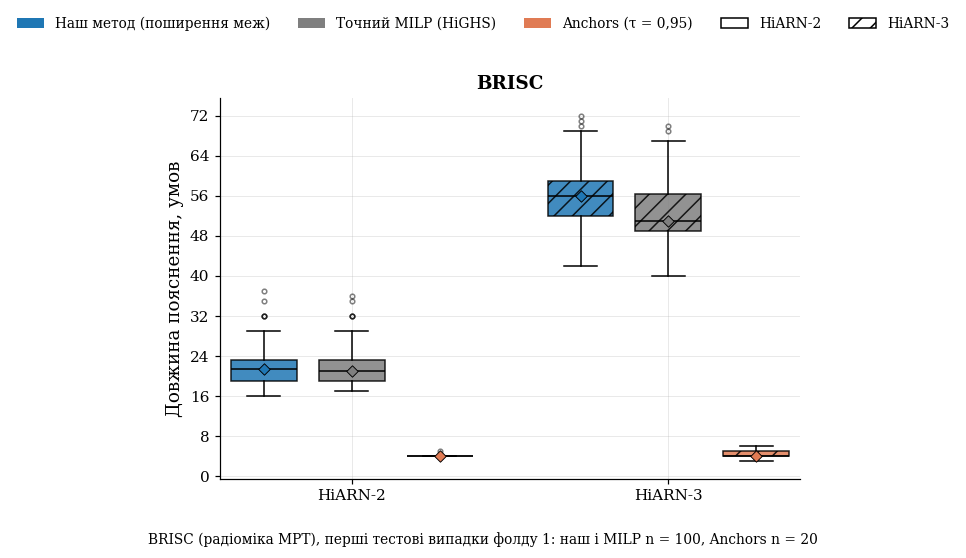

  збережено fig_e5e_time_ua (.png, .svg)


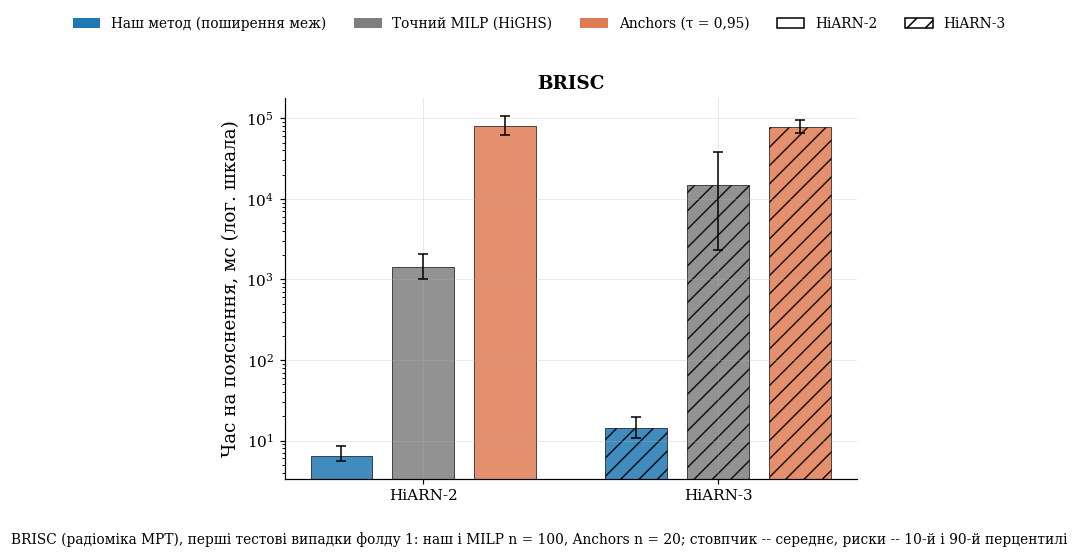

  збережено fig_e5e_violations_ua (.png, .svg)


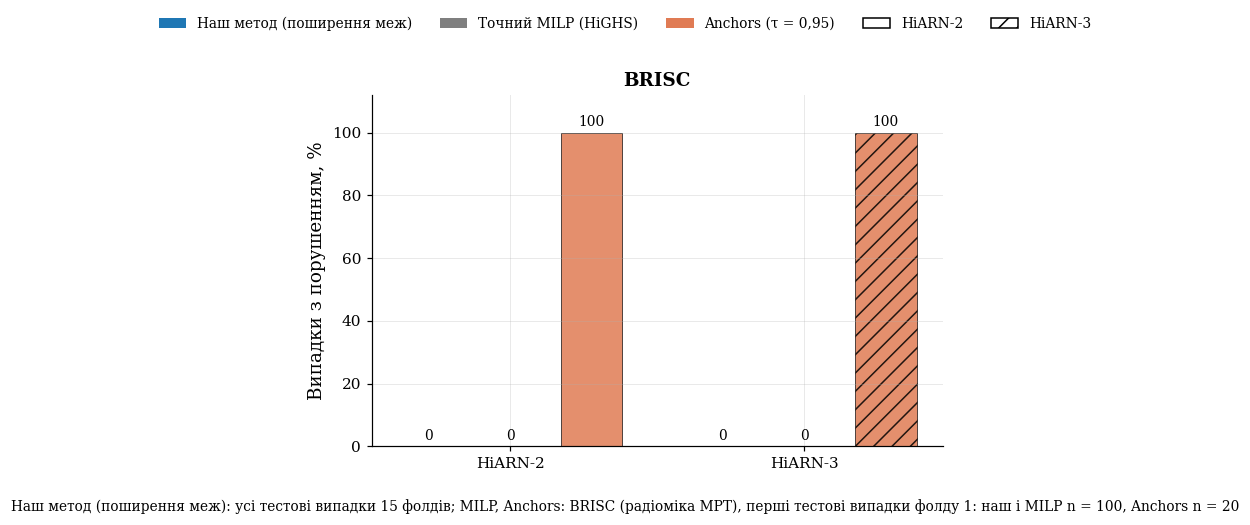

  збережено fig_e5e_length_dist_ua (.png, .svg)


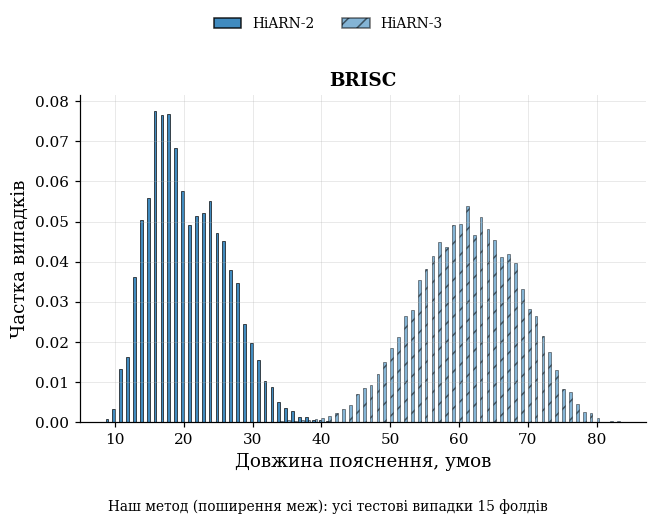

── EN ──
  збережено fig_e5e_length_en (.png, .svg)


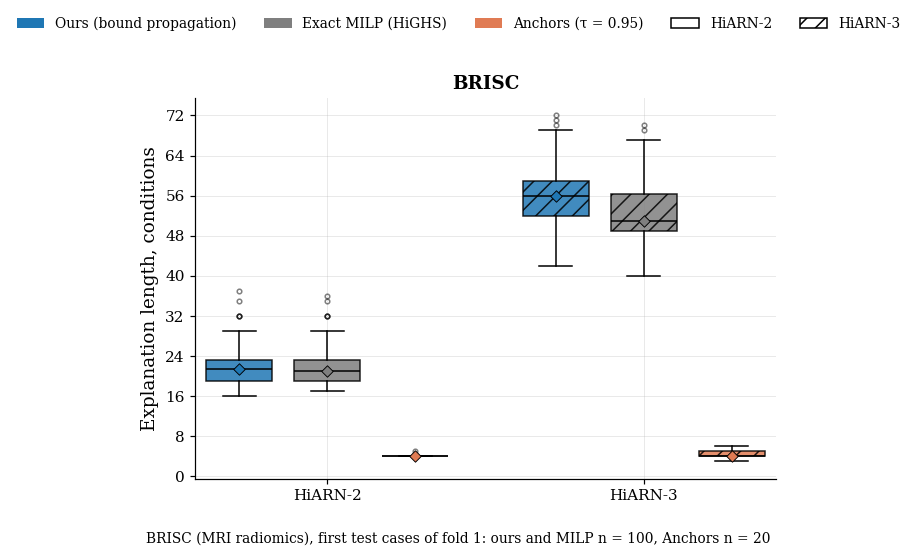

  збережено fig_e5e_time_en (.png, .svg)


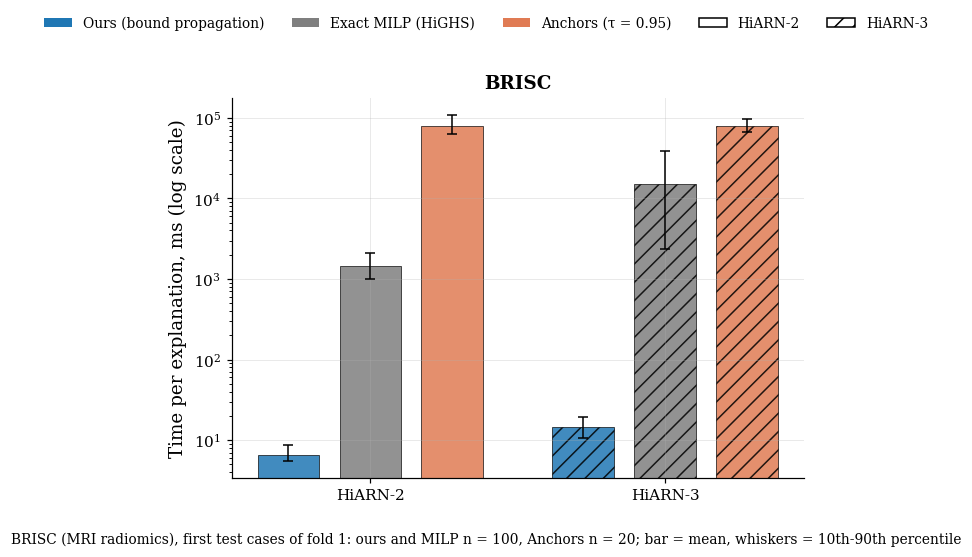

  збережено fig_e5e_violations_en (.png, .svg)


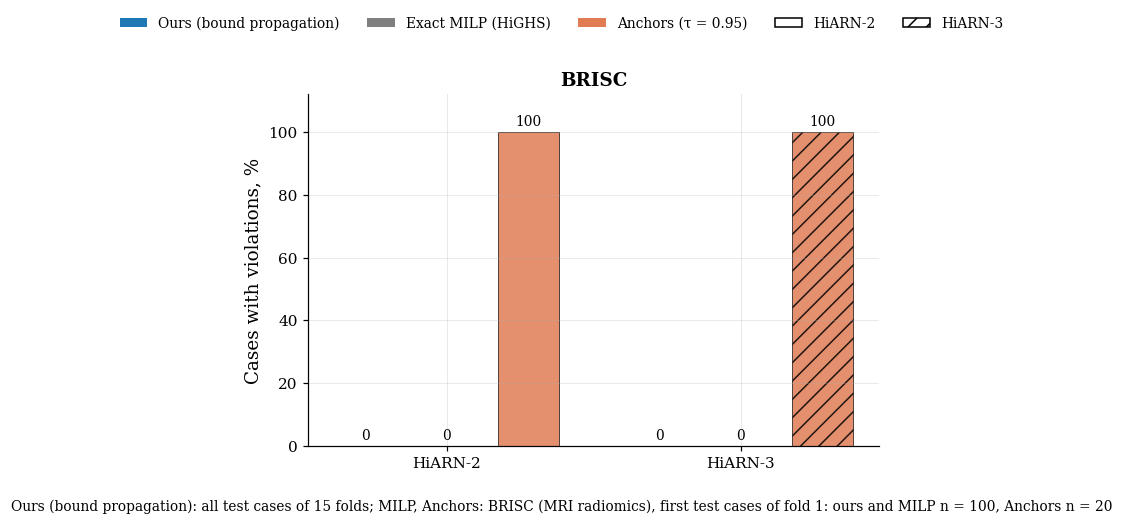

  збережено fig_e5e_length_dist_en (.png, .svg)


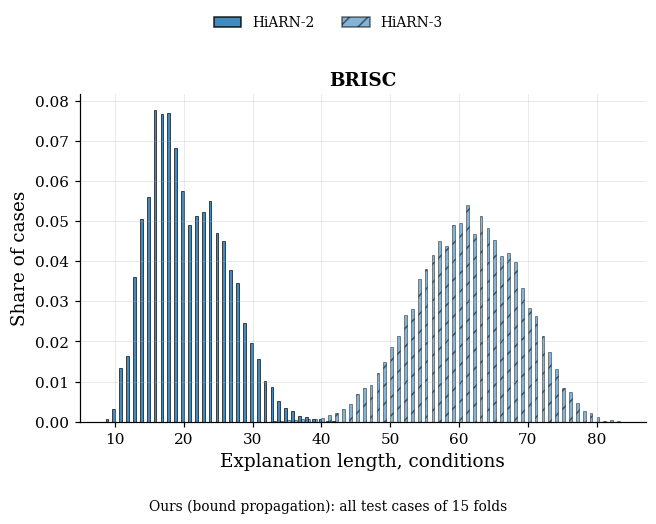

Рисунки: /content/drive/MyDrive/HiARN/E5E/plots
✅ Cell 7 (двомовні графіки) завершено за 0:00:09 | від старту 0:57:18 | 14:52:57 (Київ)
🏁 УСІ КОМІРКИ ЗАВЕРШЕНО


In [7]:
import json, os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

if 'res' not in globals():
    res = json.load(open(f'{OUT}/' + ('e5e_smoke.json' if SMOKE else 'e5e_results.json'), encoding='utf-8'))
PLOT_DIR = f'{OUT}/plots' + ('_smoke' if res.get('smoke') else '')
plt.rcParams.update({'font.family': 'DejaVu Serif', 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
                     'axes.titleweight': 'bold', 'legend.fontsize': 9, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.3,
                     'grid.linewidth': 0.6, 'figure.dpi': 110, 'savefig.dpi': 300})
DSETS = list(res['datasets'])
ARCHS = ('H2', 'H3')
ARCH_NAME = {'H2': 'HiARN-2', 'H3': 'HiARN-3'}
METH = ('ours', 'milp', 'anchor')
MCOL = {'ours': '#1f77b4', 'milp': '#7f7f7f', 'anchor': '#e07b54'}
KEYS = {'len': {'ours': 'cmp_ours_len', 'milp': 'milp_len', 'anchor': 'anchor_len'},
        'ms': {'ours': 'cmp_ours_ms', 'milp': 'milp_ms', 'anchor': 'anchor_ms'}}
L = {'ua': {'ours': 'Наш метод (поширення меж)', 'milp': 'Точний MILP (HiGHS)', 'anchor': 'Anchors (τ = 0,95)',
            'len': 'Довжина пояснення, умов', 'ms': 'Час на пояснення, мс (лог. шкала)',
            'viol': 'Випадки з порушенням, %', 'cases': 'Частка випадків',
            'note': 'BRISC (радіоміка МРТ), перші тестові випадки фолду 1: наш і MILP n = {n}, Anchors n = {na}', 'note_all': 'усі тестові випадки 15 фолдів',
            'bar': 'стовпчик -- середнє, риски -- 10-й і 90-й перцентилі'},
     'en': {'ours': 'Ours (bound propagation)', 'milp': 'Exact MILP (HiGHS)', 'anchor': 'Anchors (τ = 0.95)',
            'len': 'Explanation length, conditions', 'ms': 'Time per explanation, ms (log scale)',
            'viol': 'Cases with violations, %', 'cases': 'Share of cases',
            'note': 'BRISC (MRI radiomics), first test cases of fold 1: ours and MILP n = {n}, Anchors n = {na}', 'note_all': 'all test cases of 15 folds',
            'bar': 'bar = mean, whiskers = 10th-90th percentile'}}


def save_fig(fig, stem):
    os.makedirs(PLOT_DIR, exist_ok=True)
    for ext in ('png', 'svg'):
        fig.savefig(f'{PLOT_DIR}/{stem}.{ext}', format=ext, dpi=300, bbox_inches='tight', pad_inches=0.05)
    print('  збережено', stem, '(.png, .svg)')


def finish(fig, lang, stem, note, handles):
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=len(handles), frameon=False)
    fig.text(0.5, 0.0, note, ha='center', va='top', fontsize=9)
    fig.tight_layout(rect=(0, 0.02, 1, 0.9)); save_fig(fig, stem); plt.show(); plt.close(fig)


def meth_handles(lang):
    return ([Patch(facecolor=MCOL[m], label=L[lang][m]) for m in METH]
            + [Patch(facecolor='white', edgecolor='k', label='HiARN-2'),
               Patch(facecolor='white', edgecolor='k', hatch='//', label='HiARN-3')])


def pos(ai, mi): return ai * 3.6 + mi


def axes_common(ax, ds, ylabel):
    ax.set_xticks([pos(0, 1), pos(1, 1)]); ax.set_xticklabels([ARCH_NAME[a] for a in ARCHS])
    ax.set_title(ds); ax.set_ylabel(ylabel if ds == DSETS[0] else '')


def cmp_n(): return res['datasets'][DSETS[0]]['H2']['cmp_n']


def cmp_na(): return res['datasets'][DSETS[0]]['H2']['cmp_n_anchor']


def fig_length(lang):
    fig, axs = plt.subplots(1, len(DSETS), figsize=(4.6 * len(DSETS) + 1.5, 4.8), squeeze=False)
    for ax, ds in zip(axs[0], DSETS):
        for ai, a in enumerate(ARCHS):
            raw = res['datasets'][ds][a]['cmp_raw']
            for mi, m in enumerate(METH):
                bp = ax.boxplot([raw[KEYS['len'][m]]], positions=[pos(ai, mi)], widths=0.75, patch_artist=True,
                                flierprops={'markersize': 3, 'alpha': 0.5}, medianprops={'color': 'k'})
                bp['boxes'][0].set(facecolor=MCOL[m], alpha=0.85, hatch='//' if a == 'H3' else '')
                ax.scatter(pos(ai, mi), np.median(raw[KEYS['len'][m]]), marker='D', s=28, color=MCOL[m],
                           edgecolor='k', linewidth=0.6, zorder=3)
        axes_common(ax, ds, L[lang]['len']); ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    finish(fig, lang, f'fig_e5e_length_{lang}', L[lang]['note'].format(n=cmp_n(), na=cmp_na()), meth_handles(lang))


def fig_time(lang):
    fig, axs = plt.subplots(1, len(DSETS), figsize=(4.6 * len(DSETS) + 1.5, 4.8), squeeze=False)
    for ax, ds in zip(axs[0], DSETS):
        for ai, a in enumerate(ARCHS):
            raw = res['datasets'][ds][a]['cmp_raw']
            for mi, m in enumerate(METH):
                v = np.array(raw[KEYS['ms'][m]]); mu = v.mean()
                ax.bar(pos(ai, mi), mu, 0.75, color=MCOL[m], alpha=0.85, hatch='//' if a == 'H3' else '',
                       edgecolor='k', linewidth=0.5)
                ax.errorbar(pos(ai, mi), mu, yerr=[[mu - np.percentile(v, 10)], [np.percentile(v, 90) - mu]],
                            color='k', capsize=3, linewidth=1)
        ax.set_yscale('log'); axes_common(ax, ds, L[lang]['ms'])
    finish(fig, lang, f'fig_e5e_time_{lang}', L[lang]['note'].format(n=cmp_n(), na=cmp_na()) + '; ' + L[lang]['bar'], meth_handles(lang))


def fig_viol(lang):
    fig, axs = plt.subplots(1, len(DSETS), figsize=(4.6 * len(DSETS) + 1.5, 4.5), squeeze=False)
    for ax, ds in zip(axs[0], DSETS):
        for ai, a in enumerate(ARCHS):
            r = res['datasets'][ds][a]
            vals = {'ours': 100 * r['ours_viol'] / r['n'], 'milp': 100 * r['cmp_milp_viol'] / r['cmp_n'],
                    'anchor': 100 * r['cmp_anchor_viol_share']}
            for mi, m in enumerate(METH):
                ax.bar(pos(ai, mi), vals[m], 0.75, color=MCOL[m], alpha=0.85, hatch='//' if a == 'H3' else '',
                       edgecolor='k', linewidth=0.5)
                ax.text(pos(ai, mi), vals[m] + 2, f'{vals[m]:.0f}', ha='center', fontsize=9)
        ax.set_ylim(0, 112); axes_common(ax, ds, L[lang]['viol'])
    note = f'{L[lang]["ours"]}: {L[lang]["note_all"]}; MILP, Anchors: ' + L[lang]['note'].format(n=cmp_n(), na=cmp_na())
    finish(fig, lang, f'fig_e5e_violations_{lang}', note, meth_handles(lang))


def fig_len_dist(lang):
    fig, axs = plt.subplots(1, len(DSETS), figsize=(4.6 * len(DSETS) + 1.5, 4.5), squeeze=False)
    for ax, ds in zip(axs[0], DSETS):
        for ai, a in enumerate(ARCHS):
            cnts = res['datasets'][ds][a]['ours_len_counts']
            x = np.array([int(k) for k in cnts]); n = np.array(list(cnts.values()), float)
            ax.bar(x + (ai - 0.5) * 0.4, n / n.sum(), 0.4, color=MCOL['ours'], alpha=0.85 if a == 'H2' else 0.55,
                   hatch='//' if a == 'H3' else '', edgecolor='k', linewidth=0.5)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_title(ds); ax.set_xlabel(L[lang]['len']); ax.set_ylabel(L[lang]['cases'] if ds == DSETS[0] else '')
    h = [Patch(facecolor=MCOL['ours'], alpha=0.85, edgecolor='k', label='HiARN-2'),
         Patch(facecolor=MCOL['ours'], alpha=0.55, edgecolor='k', hatch='//', label='HiARN-3')]
    finish(fig, lang, f'fig_e5e_length_dist_{lang}', f'{L[lang]["ours"]}: {L[lang]["note_all"]}', h)


for lang in ('ua', 'en'):
    print(f'── {lang.upper()} ──')
    fig_length(lang); fig_time(lang); fig_viol(lang); fig_len_dist(lang)
print('Рисунки:', PLOT_DIR)
cell_done(7, 'двомовні графіки')
print('🏁 УСІ КОМІРКИ ЗАВЕРШЕНО')